# Spike type prediction from recording

This notebook calculates an average spike triggered wavelet spectrogram for each spike type.

## Initialization - don't change

In [15]:
import sys
sys.path.append('..')

from workflows.run_util.io import collect_paths_from_table
from param_classes.workflows.wavelet_analysis import (
    SpikeTriggeredWaveletWorkflowParams
)
from workflows.triggered_wavelet_analysis import run_analysis

params = SpikeTriggeredWaveletWorkflowParams()

## Color settings

Set the colors that will be used for coloring the markers on the strip plot and the cellwise average firing frequency curve.

In [16]:
params.palette = {
    'cell_type': {
        'PYR_L2-3': '#803300ff',
        'PYR_L4-6': '#502d16ff',
        'RSI_L2-3': '#ff48a3ff',
        'RSI_L4-6': '#800080ff',
        'FSI_L2-3': '#d54500ff',
        'FSI_L4-6': '#7a0000ff'
    },
    'spike_type': {
        'AIS-AP': "#3150B7",
        'RA-AP': '#00ff00',
        'UNKNOWN': '#000000b2'
    }
}

## Data settings

Set raw input dir. You need to give the base path where the group directories can be found.

In [17]:
params.data.raw_data.path='C:\\Datasets\\raap\\invivo'
params.data.raw_data.extension='mat'

Set the base path of the directory where csv files containing the spike features and categories can be found.
> It needs to be the same structure as the `raw_data` directory.

In [18]:
params.data.spike_features.path = 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\SpikeFeatures'
params.data.spike_features.extension = 'csv'

## Input-output settings

Set the Excel table containing the cell attributes, grouping and selector information.

In [19]:
params.input = {
    'mode': 'table',
    'table_path': 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\data_invivo.xlsx',
    'select_rules': [
        {'selected': 1}
    ]
}

Set the output base directory path. All results of this analysis (cellwise aggregated tables, grouped results, figures, statistics) is going to saved there.

In [20]:
params.output.path = 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\Preprocessed\\SpikeTypePrediction'

## Analysis parameters

 - `params.analysis.spike_types`: the list of the spike types to use as trigger

In [21]:
params.analysis.spike_types = ['AIS-AP', 'UNKNOWN', 'RA-AP']

In [22]:
type_to_id = {
    'AIS-AP': 0,
    'UNKNOWN': 1,
    'RA-AP': 2
}

## Analysis

In [23]:
input_files = collect_paths_from_table(params.data, params.input)

In [24]:
input_file = input_files[0]
data = input_file.data.load()
spikes = data.spikes
starts, ends = data.get_episode_ends('delta')

In [ ]:
import numpy as np
import pandas as pd

spike_properties = []
for _, spike in spikes.iterrows():
    spike_time = spike['timestamp']
    if spike['spike_type'] == 'UNKNOWN':
        continue
    properties = {'y': type_to_id[spike['spike_type']]}
    if np.logical_not(np.any(ends <= spike_time)):
        continue
    properties['last_delta_start'] = spike_time - np.max(starts[starts<=spike_time])
    properties['last_delta_end'] = spike_time - np.max(ends[ends<=spike_time])
    spike_properties.append(properties)

df = pd.DataFrame(spike_properties)

In [26]:
df

,y,last_delta_start,last_delta_end
0,0,0.296323,0.131758
1,0,0.377017,0.212452
2,0,0.450713,0.286148
3,0,0.707587,0.543023
4,0,0.768395,0.603830
...,...,...,...
2887,0,7.412177,7.286065
2888,0,7.720975,7.594862
2889,1,7.757840,7.631728
2890,0,8.372227,8.246115


In [27]:
probs = []
bins = np.arange(0, 0.5, 0.005)
centers = (bins[:-1] + bins[1:]) / 2
for y in df['y'].unique():
    count, _ = np.histogram(
        df.loc[df['y'] == y]['last_delta_start'].to_numpy(),
        bins=bins
    )
    probs.append(pd.DataFrame({
        'centers': centers,
        'prob': count / np.sum(count),
        'y': y
    }))
prob_df = pd.concat(probs, ignore_index=True)

In [28]:
prob_df

,centers,prob,y
0,0.0025,0.000000,0
1,0.0075,0.000000,0
2,0.0125,0.000000,0
3,0.0175,0.000000,0
4,0.0225,0.001953,0
...,...,...,...
292,0.4725,0.025641,1
293,0.4775,0.025641,1
294,0.4825,0.008547,1
295,0.4875,0.008547,1


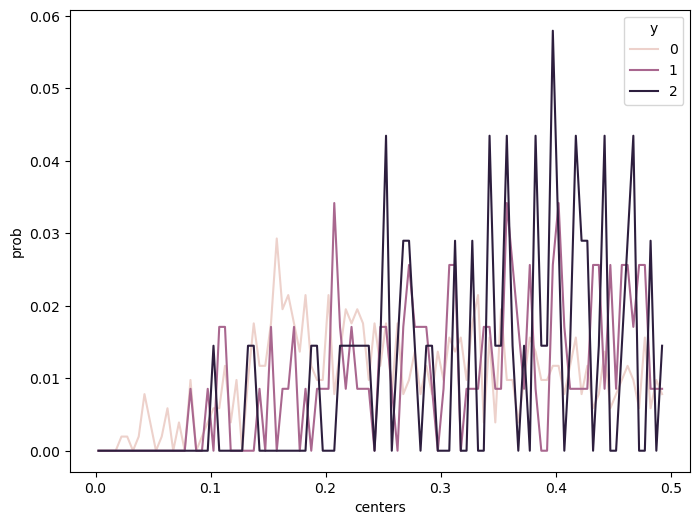

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.lineplot(
    data=prob_df,
    x='centers',
    y='prob',
    hue='y'
)
plt.show()

In [31]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

X, y = df[['last_delta_start', 'last_delta_end']], df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gnb = GaussianNB()
y_pred = gnb.fit(X_train, y_train).predict(X_test)
cfm = confusion_matrix(y_test, y_pred)
cfm

array([[133,   0, 284],
       [ 11,   0,  85],
       [  5,   0,  61]])